In [1]:
import sys
sys.path.append("..")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from src.data import (load_data, split_X_y, NUMERIC_COLS, CATEGORICAL_COLS, FEATURE_COLS,
                      CLASS_ORDER, RESULTS_DIR)

train, test = load_data()
X, y = split_X_y(train)
print(X.shape, y.shape)

(175341, 42) (175341,)


In [2]:
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(X_tr.shape, X_val.shape)
print("Worms in train / validation:", (y_tr == "Worms").sum(), "/", (y_val == "Worms").sum())

(140272, 42) (35069, 42)
Worms in train / validation: 104 / 26


In [3]:
def build_preprocessor(scale=True, log=True, numeric_cols=NUMERIC_COLS, categorical_cols=CATEGORICAL_COLS):
    one_hot = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)

    if scale:
        steps = []
        if log:
            steps.append(("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
        steps.append(("scale", StandardScaler()))
        numeric = Pipeline(steps)
    else:
        numeric = "passthrough"

    return ColumnTransformer([
        ("num", numeric, numeric_cols),
        ("cat", one_hot, categorical_cols),
    ])

In [4]:
pre = build_preprocessor(scale=True)
Z_tr = pre.fit_transform(X_tr)
Z_val = pre.transform(X_val)
print("columns after preprocessing:", Z_tr.shape[1])

names = pre.get_feature_names_out()
print("one-hot columns per categorical feature:",
      {c: sum(n.startswith(f"cat__{c}_") for n in names) for c in CATEGORICAL_COLS})
num_block = Z_tr[:, :len(NUMERIC_COLS)]
print("scaled numeric block on train: mean ≈", num_block.mean().round(3), "| std ≈", num_block.std().round(3))

weird_row = X_val.head(1).assign(state="ACC")
print("never-seen category handled, output shape:", pre.transform(weird_row).shape)

columns after preprocessing: 191
one-hot columns per categorical feature: {'proto': 133, 'service': 13, 'state': 6}
scaled numeric block on train: mean ≈ 0.0 | std ≈ 1.0
never-seen category handled, output shape: (1, 191)


In [5]:
results = []
per_class_f1 = {}
predictions = {}

def evaluate(name, y_pred, fit_seconds):
    row = {
        "model": name,
        "accuracy": accuracy_score(y_val, y_pred),
        "macro_f1": f1_score(y_val, y_pred, average="macro"),
        "balanced_acc": balanced_accuracy_score(y_val, y_pred),
        "fit_s": round(fit_seconds, 1),
    }
    results.append(row)
    per_class_f1[name] = f1_score(y_val, y_pred, average=None, labels=CLASS_ORDER)
    predictions[name] = y_pred
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items()})

def timed_fit(model, X, y, **fit_params):
    start = time.perf_counter()
    model.fit(X, y, **fit_params)
    return time.perf_counter() - start

In [6]:
dummy = DummyClassifier(strategy="most_frequent")
fit_s = timed_fit(dummy, X_tr, y_tr)
evaluate("Dummy", dummy.predict(X_val), fit_s)

{'model': 'Dummy', 'accuracy': 0.319, 'macro_f1': 0.048, 'balanced_acc': 0.1, 'fit_s': 0.1}


In [ ]:
logreg = Pipeline([
    ("pre", build_preprocessor(scale=True)),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
fit_s = timed_fit(logreg, X_tr, y_tr)
pred = logreg.predict(X_val)
evaluate("LogReg", pred, fit_s)
print(classification_report(y_val, pred, labels=CLASS_ORDER, digits=3, zero_division=0))

In [ ]:
logreg_nolog = Pipeline([
    ("pre", build_preprocessor(scale=True, log=False)),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
timed_fit(logreg_nolog, X_tr, y_tr)
print("macro-F1 with log   :", round(f1_score(y_val, predictions["LogReg"], average="macro"), 3))
print("macro-F1 without log:", round(f1_score(y_val, logreg_nolog.predict(X_val), average="macro"), 3))

macro-F1 with log   : 0.424
macro-F1 without log: 0.408


In [ ]:
rf = Pipeline([
    ("pre", build_preprocessor(scale=False)),
    ("model", RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=42)),
])
fit_s = timed_fit(rf, X_tr, y_tr)
evaluate("RandomForest", rf.predict(X_val), fit_s)

{'model': 'RandomForest', 'accuracy': 0.758, 'macro_f1': 0.582, 'balanced_acc': 0.599, 'fit_s': 8.6}


In [ ]:
rf_noweights = Pipeline([
    ("pre", build_preprocessor(scale=False)),
    ("model", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)),
])
timed_fit(rf_noweights, X_tr, y_tr)
pred_nw = rf_noweights.predict(X_val)

from sklearn.metrics import precision_score
weights_effect = pd.DataFrame({
    "recall (balanced)": recall_score(y_val, predictions["RandomForest"], labels=CLASS_ORDER, average=None, zero_division=0),
    "recall (no weights)": recall_score(y_val, pred_nw, labels=CLASS_ORDER, average=None, zero_division=0),
    "precision (balanced)": precision_score(y_val, predictions["RandomForest"], labels=CLASS_ORDER, average=None, zero_division=0),
    "precision (no weights)": precision_score(y_val, pred_nw, labels=CLASS_ORDER, average=None, zero_division=0),
}, index=CLASS_ORDER)
weights_effect.round(3)

,recall (balanced),recall (no weights),precision (balanced),precision (no weights)
Normal,0.859,0.929,0.986,0.944
Generic,0.979,0.980,0.999,0.998
Exploits,0.530,0.845,0.859,0.628
Fuzzers,0.866,0.750,0.668,0.767
DoS,0.193,0.191,0.292,0.288
Reconnaissance,0.785,0.734,0.846,0.920
Analysis,0.205,0.128,0.050,0.662
Backdoor,0.169,0.106,0.019,0.673
Shellcode,0.793,0.674,0.606,0.708
Worms,0.615,0.115,0.696,0.375


In [ ]:
le = LabelEncoder().fit(y_tr)
y_tr_num = le.transform(y_tr)
row_weights = compute_sample_weight("balanced", y_tr)

xgb = Pipeline([
    ("pre", build_preprocessor(scale=False)),
    ("model", XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=8,
                            tree_method="hist", n_jobs=-1, random_state=42)),
])
fit_s = timed_fit(xgb, X_tr, y_tr_num, model__sample_weight=row_weights)
evaluate("XGBoost", le.inverse_transform(xgb.predict(X_val)), fit_s)

{'model': 'XGBoost', 'accuracy': 0.775, 'macro_f1': 0.617, 'balanced_acc': 0.672, 'fit_s': 50.8}


In [ ]:
knn = Pipeline([
    ("pre", build_preprocessor(scale=True)),
    ("model", KNeighborsClassifier(n_neighbors=5, n_jobs=-1)),
])
fit_s = timed_fit(knn, X_tr, y_tr)
start = time.perf_counter()
knn_pred = knn.predict(X_val)
print(f"k-NN predict took {time.perf_counter() - start:.0f} s")
evaluate("kNN", knn_pred, fit_s)

k-NN predict took 9 s
{'model': 'kNN', 'accuracy': 0.798, 'macro_f1': 0.531, 'balanced_acc': 0.51, 'fit_s': 0.8}


In [ ]:
nb = Pipeline([
    ("pre", build_preprocessor(scale=True)),
    ("model", GaussianNB()),
])
fit_s = timed_fit(nb, X_tr, y_tr, model__sample_weight=compute_sample_weight("balanced", y_tr))
evaluate("NaiveBayes", nb.predict(X_val), fit_s)

{'model': 'NaiveBayes', 'accuracy': 0.134, 'macro_f1': 0.059, 'balanced_acc': 0.255, 'fit_s': 1.5}


In [ ]:
table = pd.DataFrame(results).set_index("model").sort_values("macro_f1", ascending=False)
table.to_csv(RESULTS_DIR / "phase3_single_split.csv")
table.round(3)

,accuracy,macro_f1,balanced_acc,fit_s
model,,,,
XGBoost,0.775,0.617,0.672,50.8
RandomForest,0.758,0.582,0.599,8.6
kNN,0.798,0.531,0.510,0.8
LogReg,0.683,0.424,0.603,729.4
NaiveBayes,0.134,0.059,0.255,1.5
Dummy,0.319,0.048,0.100,0.1


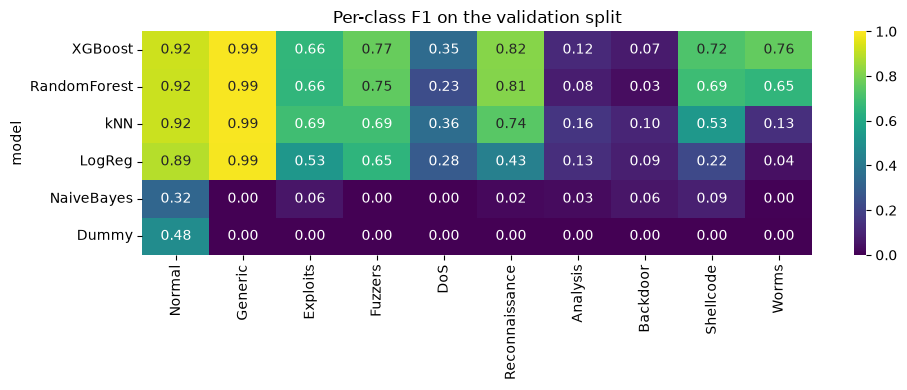

In [ ]:
f1_table = pd.DataFrame(per_class_f1, index=CLASS_ORDER).T.loc[table.index]
f1_table.to_csv(RESULTS_DIR / "phase3_per_class_f1.csv")

plt.figure(figsize=(10, 4))
sns.heatmap(f1_table, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Per-class F1 on the validation split")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig_phase3_per_class_f1.png", dpi=200)
plt.show()

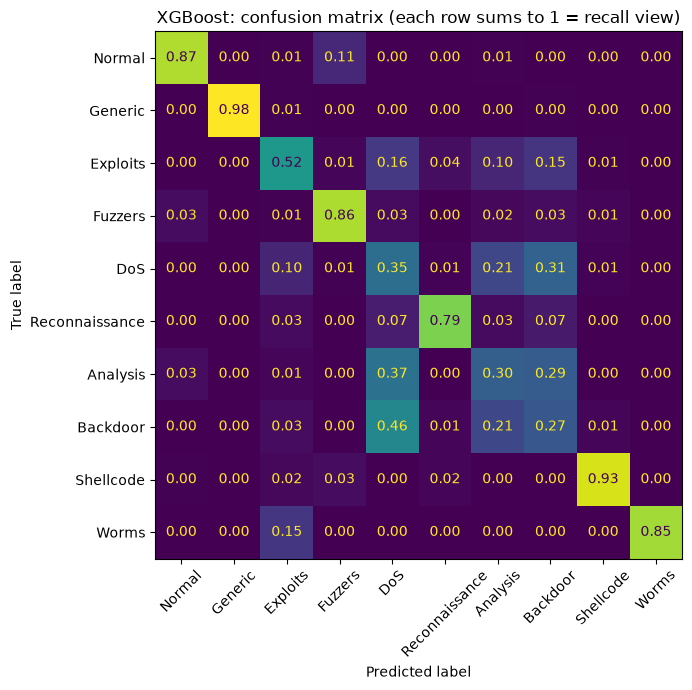

In [ ]:
best = table.index[0]
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_val, predictions[best], labels=CLASS_ORDER, normalize="true",
                                        values_format=".2f", xticks_rotation=45, ax=ax, colorbar=False)
ax.set_title(f"{best}: confusion matrix (each row sums to 1 = recall view)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig_phase3_confusion_best.png", dpi=200)
plt.show()